# Übung 4: Interaktive Datenvisualisierung

In dieser Übung vergleichst du statische Visualisierungen mit **plotnine** und interaktive Visualisierungen mit **Plotly**. Entscheidend ist nicht die Anzahl der Interaktionen, sondern ihr Beitrag zu einer konkreten Analysefrage.

> **Overview first, zoom and filter, then details-on-demand.** — Ben Shneiderman

## Aufbau und Zeitplanung

**Pflichtteil (60-70 Minuten)**

1. Histogramm: statisch und interaktiv
2. Bubble Chart: drei Variablen und Details-on-demand
3. Dropdown: Überblick und Kontinentfilter
4. Koordinierte Ansichten: gemeinsamer Filter für zwei Diagramme

**Wahlaufgaben:** Range Slider sowie Vergleich von Anteilsdiagrammen  
**Bonus:** Kennzahlenwechsel für ausgewählte Länder und Annotation

Die Aufgaben bauen aufeinander auf. Bearbeite zuerst den Pflichtteil.

## Lernziele

Nach der Bearbeitung kannst du:

- eine statische und eine interaktive Visualisierung für dieselbe Analysefrage erstellen und vergleichen,
- die Bestandteile einer Plotly-Figur als Daten-Traces, Layout und gegebenenfalls Frames erklären,
- Tooltips, Legenden, Dropdowns und Zeitfilter zielgerichtet einsetzen,
- mehrere Ansichten durch einen gemeinsamen Filter koordinieren,
- Nutzen und Grenzen einer Interaktion anhand der Analyseaufgabe begründen.

## Vorbereitung

Führe die Installationszelle nur aus, wenn ein Import in der folgenden Zelle fehlschlägt. Nach einer Installation kann ein Neustart des Kernels erforderlich sein.

In [1]:
# Bei Bedarf das Kommentarzeichen in der nächsten Zeile entfernen:
# %pip install plotly pandas plotnine statsmodels

In [2]:
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import plotnine as p9

## Daten laden und prüfen

Wir verwenden eine einzige, in Plotly enthaltene Version des Gapminder-Datensatzes. Die Daten enden 2007 und enthalten Beobachtungen in Fünfjahresschritten.

In [3]:
df = px.data.gapminder()
year = 2007
df_2007 = df.loc[df["year"] == year].copy()

print(f"Zeilen: {len(df):,}")
print(f"Länder: {df['country'].nunique()}")
print(f"Jahre: {df['year'].min()}–{df['year'].max()} in Schritten von {sorted(df['year'].unique())[:3]} …")
df_2007.head()

Zeilen: 1,704
Länder: 142
Jahre: 1952–2007 in Schritten von [np.int64(1952), np.int64(1957), np.int64(1962)] …


,country,continent,year,lifeExp,pop,gdpPercap,iso_alpha,iso_num
11,Afghanistan,Asia,2007,43.828,31889923,974.580338,AFG,4
23,Albania,Europe,2007,76.423,3600523,5937.029526,ALB,8
35,Algeria,Africa,2007,72.301,33333216,6223.367465,DZA,12
47,Angola,Africa,2007,42.731,12420476,4797.231267,AGO,24
59,Argentina,Americas,2007,75.320,40301927,12779.379640,ARG,32


In [4]:
required_columns = {"country", "continent", "year", "lifeExp", "pop", "gdpPercap"}
assert required_columns.issubset(df.columns), "Erwartete Gapminder-Spalten fehlen."
assert len(df_2007) == df['country'].nunique(), "Für 2007 wird eine Zeile je Land erwartet."
print("Datenprüfung erfolgreich.")

Datenprüfung erfolgreich.


## Geführtes Beispiel: dieselbe Frage, zwei Werkzeuge

**Frage:** Wie hängt das BIP pro Kopf im Jahr 2007 mit der Lebenserwartung zusammen?

Die logarithmische X-Achse erleichtert den Vergleich stark unterschiedlich großer BIP-Werte. Die interaktive Version ergänzt Ländernamen im Hover.

In [5]:
fig = px.scatter(
    df_2007,
    x="gdpPercap",
    y="lifeExp",
    color="continent",
    hover_name="country",
    log_x=True,
    labels={
        "gdpPercap": "BIP pro Kopf (US-Dollar, Log-Skala)",
        "lifeExp": "Lebenserwartung (Jahre)",
        "continent": "Kontinent",
    },
    title="BIP pro Kopf und Lebenserwartung (2007)",
)
fig.show()

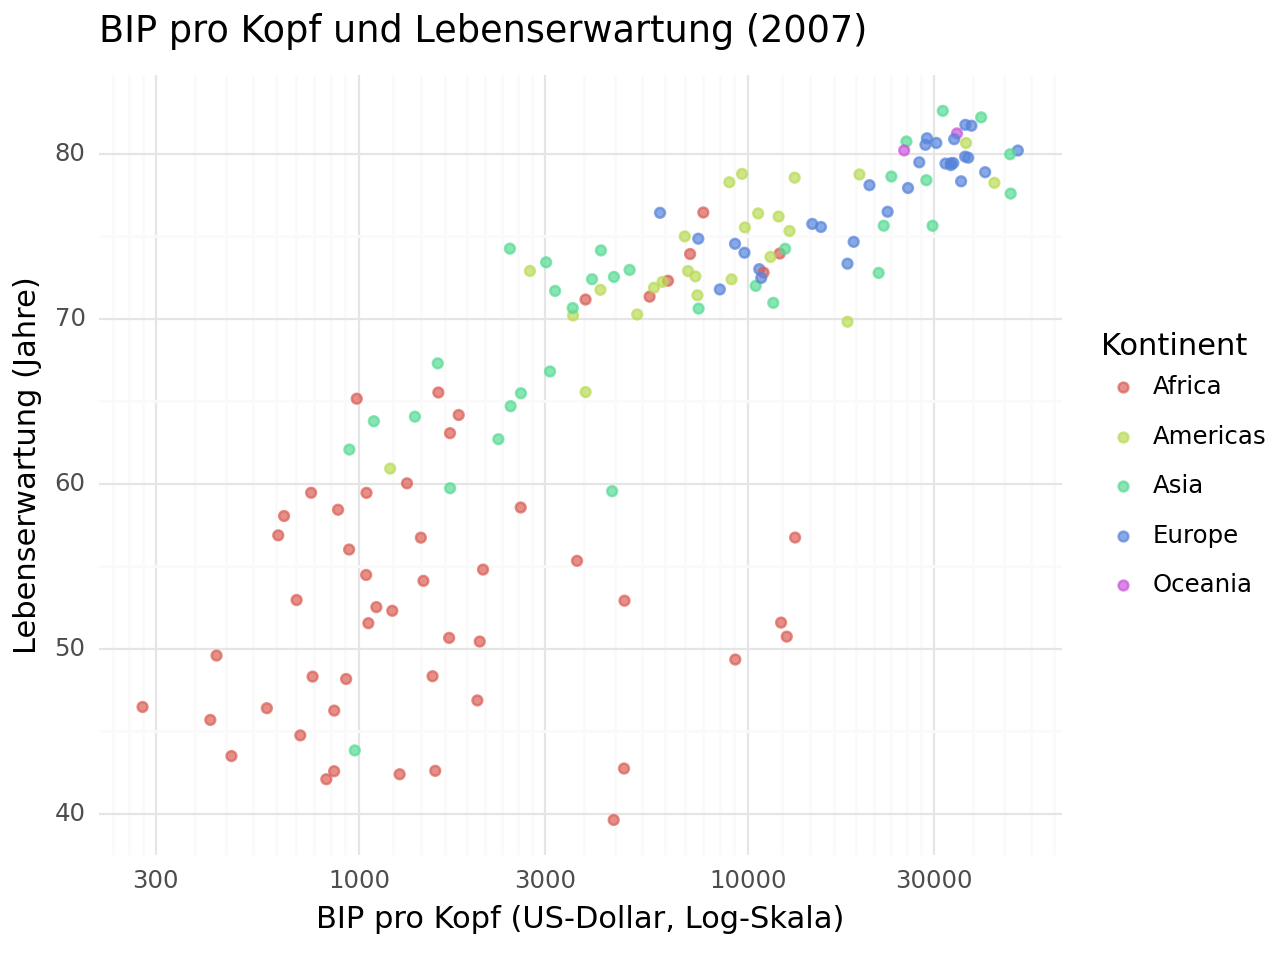

<Figure Size: (640 x 480)>

In [6]:
scatter_static = (
    p9.ggplot(df_2007, p9.aes(x="gdpPercap", y="lifeExp", color="continent"))
    + p9.geom_point(alpha=0.7)
    + p9.scale_x_log10()
    + p9.labs(
        title="BIP pro Kopf und Lebenserwartung (2007)",
        x="BIP pro Kopf (US-Dollar, Log-Skala)",
        y="Lebenserwartung (Jahre)",
        color="Kontinent",
    )
    + p9.theme_minimal()
)
scatter_static

### Optional: Regressionslinie fachlich einordnen

Eine Regressionslinie beschreibt einen statistischen Zusammenhang, aber keine Kausalität. Durch `trendline_options=dict(log_x=True)` wird für das Modell der logarithmierte X-Wert verwendet; `log_x=True` steuert zusätzlich die Darstellung der Achse.

In [7]:
fig_reg = px.scatter(
    df_2007, x="gdpPercap", y="lifeExp", hover_name="country",
    log_x=True, trendline="ols", trendline_options={"log_x": True},
    labels={"gdpPercap": "BIP pro Kopf (US-Dollar, Log-Skala)", "lifeExp": "Lebenserwartung (Jahre)"},
    title="Statistischer Zusammenhang zwischen BIP pro Kopf und Lebenserwartung (2007)",
)
fig_reg.show()

## Plotly-Mikrobeispiel: Dropdown und Sichtbarkeit

Plotly Express erzeugt ein `go.Figure`-Objekt. In diesem Beispiel erstellt `color="continent"` einen Trace je Kontinent. Ein Dropdown setzt für jeden Button eine Sichtbarkeitsmaske in derselben Reihenfolge wie `fig.data`.

In [8]:
demo = px.scatter(
    df_2007, x="gdpPercap", y="lifeExp", color="continent",
    hover_name="country", log_x=True, title="Dropdown-Mikrobeispiel",
)
trace_names = [trace.name for trace in demo.data]
buttons = [
    dict(label="Alle Kontinente", method="update",
         args=[{"visible": [True] * len(demo.data)}, {"title": "Alle Kontinente"}])
]
for continent in trace_names:
    mask = [name == continent for name in trace_names]
    buttons.append(
        dict(label=continent, method="update",
             args=[{"visible": mask}, {"title": f"Kontinent: {continent}"}])
    )
demo.update_layout(
    updatemenus=[dict(buttons=buttons, direction="down", showactive=True, x=0, y=1.15)],
    margin=dict(t=110),
)
demo.show()

---
## Pflichtaufgabe 1: Verteilung der Lebenserwartung

Erstelle für 2007 ein statisches Histogramm mit plotnine und ein interaktives Histogramm mit Plotly. Verwende in beiden Grafiken dieselbe sinnvolle Anzahl an Klassen.

**Selbstcheck**

- Beide Diagramme verwenden dieselben Daten und dieselbe Klasseneinteilung.
- Achsen, Einheit, Jahr und Titel sind eindeutig.
- Du kannst erklären, welche zusätzliche Information Hover tatsächlich liefert.

In [9]:
# TODO: Statisches Histogramm mit plotnine
n_bins = 12

hist_static = (
    p9.ggplot(df_2007, p9.aes(x="lifeExp"))
    # + p9.geom_histogram(bins=..., ...)
    # + p9.labs(...)
    # + p9.theme_minimal()
)
# hist_static

In [10]:
# TODO: Interaktives Histogramm mit Plotly Express
# hist_interactive = px.histogram(df_2007, x=..., nbins=n_bins, ...)
# hist_interactive.show()

### Reflexion zu Aufgabe 1

1. Welche Form hat die Verteilung? Gibt es Hinweise auf mehrere Gruppen?
2. Ändert Interaktivität deine Interpretation oder nur die Bedienung?
3. Welche Darstellung würdest du für einen gedruckten Bericht wählen, welche für Exploration? Begründe.

---
## Pflichtaufgabe 2: Bubble Chart

Untersuche 2007 den Zusammenhang zwischen BIP pro Kopf und Lebenserwartung. Kodiere Bevölkerung über die Punktfläche und Kontinent über Farbe. Erstelle eine statische und eine interaktive Variante.

**Achte besonders auf:** logarithmische X-Achse, sinnvolle Punktgrößen, Überdeckung und eine Legende mit klarer Einheit.

In [11]:
# TODO: Statischer Bubble Chart
bubble_static = (
    p9.ggplot(df_2007, p9.aes(x="gdpPercap", y="lifeExp", size="pop", color="continent"))
    # + p9.geom_point(alpha=...)
    # + p9.scale_x_log10()
    # + p9.scale_size_continuous(range=(... , ...))
    # + p9.labs(...)
    # + p9.theme_minimal()
)
# bubble_static

In [12]:
# TODO: Interaktiver Bubble Chart
# bubble_interactive = px.scatter(
#     df_2007, x=..., y=..., size=..., color=..., hover_name=...,
#     log_x=True, size_max=..., labels=..., title=...,
# )
# bubble_interactive.show()

In [ ]:
# Statisches Histogramm mit plotnine 
bubble_static = (
        p9.ggplot(df_2007, p9.aes(x="lifeExp"))
        + p9.geom_histogram(bins=25, # Anzahl der Bins
                            fill = "steelblue", color = "black", alpha = 0.7) # Fallfarbe, Randfarbe und Transparenz
        + p9.labs(
            title="Verteilung der Lebenserwartung (lifeExp) im Jahr 2007",
            x="Lebenserwartung (Jahre)",
            y="Anzahl Länder"
        )
        + p9.theme_minimal()
    )

print(bubble_static)

In [ ]:
# Interaktives Histogramm mit plotly.express
bubble_interactive = px.histogram(
    df_2007,
    x="lifeExp",
    nbins=25,
    title="Verteilung der Lebenserwartung (lifeExp) im Jahr 2007 – interaktiv",
    labels={
        "lifeExp": "Lebenserwartung (Jahre)",
        "count": "Anzahl Länder"
    }
)

bubble_interactive.show()

### Reflexion zu Aufgabe 2

1. Welche Länder oder Gruppen fallen auf?
2. Welche Information wird durch die Punktgröße sichtbar, welche wird verdeckt?
3. Warum darfst du aus dem dargestellten Zusammenhang keine Kausalität ableiten?
4. Welche Hover-Felder sind für die Analyse wirklich relevant?

---
## Pflichtaufgabe 3: Kontinentfilter mit Dropdown

Übertrage das Dropdown-Mikrobeispiel auf deinen Bubble Chart aus Aufgabe 2. Die Standardansicht zeigt alle Kontinente. Jede weitere Option zeigt genau einen Kontinent.

**Selbstcheck:** Der aktive Zustand ist erkennbar, die Option „Alle Kontinente“ stellt den Ausgangszustand wieder her und Hover zeigt mindestens Land, Bevölkerung und Jahr.

In [13]:
# Startfigur: ein Trace je Kontinent
fig_filter = px.scatter(
    df_2007, x="gdpPercap", y="lifeExp", size="pop", color="continent",
    hover_name="country", hover_data={"pop": ":,", "year": True},
    log_x=True, size_max=50, title="Alle Kontinente",
)

trace_names = [trace.name for trace in fig_filter.data]
buttons = []

# TODO 1: Button „Alle Kontinente“ ergänzen.
# TODO 2: In einer Schleife je Kontinent eine Sichtbarkeitsmaske erzeugen.
# TODO 3: Dropdown mit update_layout(updatemenus=[...]) einsetzen.

# fig_filter.show()

---
## Pflichtaufgabe 4: Koordinierte Ansichten mit gemeinsamem Filter

Erstelle links einen Scatterplot und rechts ein Histogramm. Ein gemeinsames Dropdown filtert beide Ansichten nach Kontinent.

> Dies ist **koordinierte Filterung**, nicht echtes Brushing & Linking. Beim Brushing würde eine direkte Auswahl von Punkten in einer Ansicht die zugehörigen Elemente der anderen Ansicht hervorheben.

Das Grundgerüst erzeugt die beiden Traces. Ergänze das Dropdown so, dass die X- und Y-Daten beider Traces gemeinsam aktualisiert werden.

In [14]:
filters = {"Alle Kontinente": df_2007}
filters.update({
    continent: df_2007.loc[df_2007["continent"] == continent]
    for continent in sorted(df_2007["continent"].unique())
})

fig_linked = make_subplots(
    rows=1, cols=2,
    subplot_titles=("BIP pro Kopf und Lebenserwartung", "Verteilung der Lebenserwartung"),
)
fig_linked.add_trace(
    go.Scatter(
        x=df_2007["gdpPercap"], y=df_2007["lifeExp"], mode="markers",
        text=df_2007["country"], name="Länder",
        hovertemplate="%{text}<br>BIP/Kopf: %{x:,.0f}<br>Lebenserwartung: %{y:.1f}<extra></extra>",
    ), row=1, col=1,
)
fig_linked.add_trace(
    go.Histogram(x=df_2007["lifeExp"], nbinsx=12, name="Verteilung"),
    row=1, col=2,
)

buttons = []
for label, subset in filters.items():
    # Die Listen in args entsprechen der Trace-Reihenfolge: Scatter, Histogramm.
    # TODO: Button mit method="update" und passenden x-/y-Listen ergänzen.
    pass

fig_linked.update_xaxes(type="log", title_text="BIP pro Kopf (US-Dollar)", row=1, col=1)
fig_linked.update_yaxes(title_text="Lebenserwartung (Jahre)", row=1, col=1)
# TODO: Dropdown einsetzen, Titel und oberen Rand anpassen.
# fig_linked.show()

### Reflexion zu Aufgabe 4

1. Welche Muster werden erst durch die Kombination beider Ansichten sichtbar?
2. Welche Information geht beim Filtern verloren?
3. Wie unterscheidet sich koordinierte Filterung von echtem Brushing?
4. Wie würdest du den aktiven Filter für eine Veröffentlichung noch deutlicher anzeigen?

---
# Wahlaufgaben

Bearbeite mindestens eine Wahlaufgabe, wenn du den Pflichtteil abgeschlossen hast.

## Wahlaufgabe 5: Zeitreihe mit Range Slider

Berechne die **ungewichtete mittlere Lebenserwartung der Länder** je Kontinent und Jahr. Erstelle ein Liniendiagramm mit Range Slider sowie Buttons für alle Jahre, die letzten 20 Jahre und die letzten 10 Jahre.

Beachte: Die Daten liegen nur alle fünf Jahre vor. Ein Zehnjahresfenster enthält deshalb nur wenige Zeitpunkte.

In [15]:
life_exp_by_continent = (
    df.groupby(["year", "continent"], as_index=False)["lifeExp"].mean()
)
life_exp_by_continent["year_date"] = pd.to_datetime(life_exp_by_continent["year"], format="%Y")

fig_time = px.line(
    life_exp_by_continent, x="year_date", y="lifeExp", color="continent", markers=True,
    labels={"year_date": "Jahr", "lifeExp": "Ungewichteter Ländermittelwert der Lebenserwartung"},
    title="Mittlere Lebenserwartung der Länder nach Kontinent",
)
# TODO: rangeslider sichtbar machen.
# TODO: rangeselector mit 10 Jahren, 20 Jahren und „Alle“ ergänzen.
# fig_time.show()

## Wahlaufgabe 6: Bevölkerungsanteile vergleichen

Aggregiere die Bevölkerung 2007 nach Kontinent. Vergleiche:

1. Treemap,
2. Donut Chart,
3. sortiertes horizontales Balkendiagramm.

Pie und Donut verwenden dieselbe Winkelkodierung. Das Balkendiagramm ergänzt bewusst eine besser vergleichbare gemeinsame Skala. Entscheide anhand einer konkreten Zielgruppe, welche Darstellung du empfehlen würdest.

In [16]:
population_by_continent = (
    df_2007.groupby("continent", as_index=False)["pop"].sum()
    .sort_values("pop", ascending=False)
)
population_by_continent["percent"] = (
    population_by_continent["pop"] / population_by_continent["pop"].sum() * 100
)
population_by_continent

,continent,pop,percent
2,Asia,3811953827,60.981376
0,Africa,929539692,14.870224
1,Americas,898871184,14.379608
3,Europe,586098529,9.376057
4,Oceania,24549947,0.392735


In [ ]:
# TODO: Erzeuge mind zwei einzelne Figuren oder eine Figur mit umschaltbaren Traces.
# Hinweise: go.Treemap(...), go.Pie(hole=0.5, ...), go.Bar(orientation="h", ...)
# Zeige im Hover absolute Bevölkerung und Prozentanteil.

---
# Bonusaufgaben

Die folgenden Aufgaben kombinieren mehrere Plotly-Konzepte. Sie sind nicht Teil des Pflichtumfangs.

## Bonus 7: Ausgewählte Länder und wechselbare Kennzahl

Begrenze die Auswahl auf höchstens acht Länder. Erzeuge einen Trace je Land und ein Dropdown für `lifeExp`, `gdpPercap` und `pop`. Aktualisiere beim Kennzahlenwechsel auch Titel, Einheit und gegebenenfalls Achsenskalierung. Vermeide eine Legende mit allen 142 Ländern.

In [18]:
selected_countries = ["Germany", "Austria", "Nigeria", "India", "China", "United States"]
country_data = df.loc[df["country"].isin(selected_countries)].copy()
country_data["year_date"] = pd.to_datetime(country_data["year"], format="%Y")
metrics = {
    "lifeExp": ("Lebenserwartung", "Jahre", False),
    "gdpPercap": ("BIP pro Kopf", "US-Dollar", True),
    "pop": ("Bevölkerung", "Personen", False),
}

# TODO: Figure mit einem Trace je Land erstellen.
# TODO: Dropdown aktualisiert y-Daten, Titel, Achsentitel und log-Einstellung.
# TODO: Range Slider ergänzen.

## Bonus 8: Nigeria und Deutschland annotieren

Vergleiche die Bevölkerung von Nigeria und Deutschland. Bestimme aus den Daten das erste beobachtete Jahr, in dem Nigeria einen höheren Wert aufweist. Verwende nicht einfach eine vorgegebene Jahreszahl, sondern berechne sie reproduzierbar. Ergänze anschließend eine Annotation.

In [19]:
comparison = (
    df.loc[df["country"].isin(["Nigeria", "Germany"]), ["country", "year", "pop"]]
    .pivot(index="year", columns="country", values="pop")
)
first_overtake_year = comparison.index[comparison["Nigeria"] > comparison["Germany"]][0]
print("Erstes beobachtetes Jahr mit Nigeria > Deutschland:", first_overtake_year)

# TODO: Liniendiagramm erstellen und fig.add_annotation(...) verwenden.

Erstes beobachtetes Jahr mit Nigeria > Deutschland: 1987


---
## Abschlussreflexion

1. Bei welcher Aufgabe hat die Interaktion eine neue Einsicht ermöglicht?
2. Wo hat sie lediglich zusätzliche Bedienung erzeugt?
3. Welche Kernbotschaft muss auch ohne Hover oder Filter sichtbar bleiben?
4. Wo stößt das Mantra „Overview first, zoom and filter, then details-on-demand“ an Grenzen?
5. Welche Anpassung wäre für kleine Bildschirme oder Tastaturbedienung erforderlich?